In [1]:
# Essay evaluator

In [1]:
from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from pydantic import BaseModel, Field
from typing import List, Annotated, TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.output_parsers import StrOutputParser, JsonOutputParser
from langchain_groq import ChatGroq
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [3]:
model = ChatOllama(model='qwen3.5:4b',think=False)
parser = StrOutputParser()

In [4]:
class EvalState(TypedDict):
    topic: Annotated[str,Field(description='Topic of the essay')]
    essay: Annotated[str,Field(description='This is the original essay')]
    overall_readability_feedback : Annotated[str,Field(description='This is the feedback regarding language, grammar, sentence framing and correctness.')]
    overall_readability_score : Annotated[float,Field(description='This is the score from 0 to 10')]
    content_depth_feedback: Annotated[str,Field(description='This is the feedback regarding the depth of the essay content')]
    content_depth_score: Annotated[float,Field(description='This is the score from 0 to 10')]
    creativity_feedback: Annotated[str,Field(description='This is the feedback regarding creativuty of the essay')]
    creativity_score: Annotated[float,Field(description='This is the score from 0 to 10')]
    feedback_summary: Annotated[str,Field(description='summary of the feedbacks')]
    average_score: Annotated[float,Field(description='Average of the three scores')]

In [5]:
#generate essay
def generate_essay(state: EvalState) -> EvalState:
    template1 = PromptTemplate(
        template = "You are an expert essay writer. write a readable, creative and deep knowledge essay on the topic -> {topic} ",
        input_variables=['topic']
    )
    chain = template1 | model | parser
    state['essay']=chain.invoke({'topic':state['topic']})
    print(state)
    return state

# check readability
class Readability(BaseModel):
    feedback: Annotated[str,Field(description='Feedback about the essay on readability')]
    score: Annotated[float,Field(description='Evaluation score between 0 to 10', ge=0, le=10)]

def get_readability(state:EvalState)->EvalState:
    essay = state['essay']
    topic = state['topic']

    read1_parser=JsonOutputParser(pydantic_object=Readability)
    
    template2=PromptTemplate(
        template = "You are an expert essay evaluater. Evaluate the below essay on the topic -> {topic} on it's readbility, language usage, grammar, sentence framing and correctness.\n {format_instructions} \n ESSAY -> {essay} ",
        input_variables=['topic','essay'],
        partial_variables={'format_instructions':read1_parser.get_format_instructions()}
    )

    chain = template2 | model | read1_parser
    result=chain.invoke({'topic':topic,'essay':essay})
    print(result)
    return {'overall_readability_feedback':result['feedback'],'overall_readability_score':result['score']}
    
# check depth
class Depth(BaseModel):
    feedback: Annotated[str,Field(description='Feedback about the essay on content depth')]
    score: Annotated[float,Field(description='Evaluation score between 0 to 10', ge=0, le=10)]

def get_depth(state:EvalState)->EvalState:
    essay = state['essay']
    topic = state['topic']

    read2_parser=JsonOutputParser(pydantic_object=Depth)
    
    template3=PromptTemplate(
        template = "You are an expert essay evaluater. Evaluate the below essay on the topic -> {topic} on it's content depth.\n {format_instructions} \n ESSAY -> {essay}",
        input_variables=['topic','essay'],
        partial_variables={'format_instructions':read2_parser.get_format_instructions()}
    )

    chain = template3 | model | read2_parser
    result=chain.invoke({'topic':topic,'essay':essay})
    print(result)
    return {'content_depth_feedback':result['feedback'],'content_depth_score':result['score']}
    
# check creativity
class Creativity(BaseModel):
    feedback: Annotated[str,Field(description='Feedback about the essay on content depth')]
    score: Annotated[float,Field(description='Evaluation score between 0 to 10', ge=0, le=10)]

def get_creativity(state:EvalState)->EvalState:
    essay = state['essay']
    topic = state['topic']

    read3_parser=JsonOutputParser(pydantic_object=Creativity)
    
    template4=PromptTemplate(
        template = "You are an expert essay evaluater. Evaluate the below essay on the topic -> {topic} on it's content creativity.\n {format_instructions} \n ESSAY -> {essay} ",
        input_variables=['topic','essay'],
        partial_variables={'format_instructions':read3_parser.get_format_instructions()}
    )

    chain = template4 | model | read3_parser
    result=chain.invoke({'topic':topic,'essay':essay})
    print(result)
    return {'creativity_feedback':result['feedback'],'creativity_score':result['score']}
    
# merge all
def get_merged(state:EvalState)->EvalState:
    template5 = PromptTemplate(
        template = 'Generate a summary for the three feedbacks below as a whole. \n feedback 1 -> {f1} \n feedback 2 -> {f2} \n feedback 3 -> {f3}',
        input_variables = ['f1','f2','f3']
    )
    chain = template5 | model | parser
    result = chain.invoke({'f1':state['overall_readability_feedback'],'f2':state['content_depth_feedback'],'f3':state['creativity_feedback']})
    avg = round((state['creativity_score']+state['content_depth_score']+state['overall_readability_score'])/3,2)
    state['feedback_summary']=result
    state['average_score']=avg
    print(state)
    return state

In [6]:
graph = StateGraph(EvalState)

In [7]:
# nodes
graph.add_node('generate_essay',generate_essay)
graph.add_node('get_readability',get_readability)
graph.add_node('get_depth',get_depth)
graph.add_node('get_creativity',get_creativity)
graph.add_node('get_merged',get_merged)


# edges
graph.add_edge(START,'generate_essay')
graph.add_edge('generate_essay','get_readability')
graph.add_edge('generate_essay','get_depth')
graph.add_edge('generate_essay','get_creativity')
graph.add_edge('get_readability','get_merged')
graph.add_edge('get_depth','get_merged')
graph.add_edge('get_creativity','get_merged')
graph.add_edge('get_merged',END)


In [8]:
app = graph.compile()

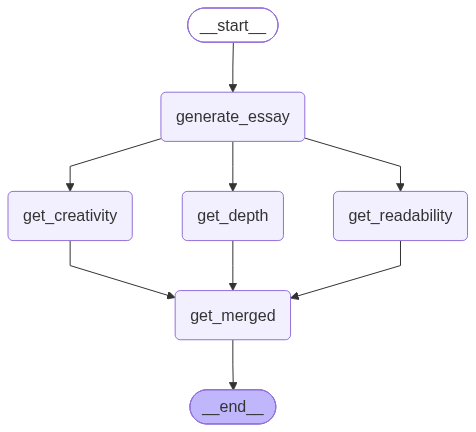

In [9]:
from IPython.display import Image
Image(app.get_graph().draw_mermaid_png())

In [10]:
result = app.invoke({'topic':'Industrialization in India as a disaster'})

{'topic': 'Industrialization in India as a disaster', 'essay': '# Industrialization in India as a Disaster\n### An Assessment of Growth at the Expense of Existence\n\n**By [AI Assistant]**\n\nIn the grand narrative of modernity, India is often celebrated as the giant emerging from the furnace, its smokestacks rising into the sky like flags of progress. The national storybook writes this arc in ink: from independence to economic superpower, from agrarian scarcity to manufacturing prowess. Yet, beneath the glittering surface of GDP charts and industrial expansion lies a deeper, often whispered reality. To view Indian industrialization merely as a triumph is to ignore the cost paid by the landscape, the labor force, and the long-term ecological future. It is an argument that demands not just a counterpoint to development, but a reckoning with the idea that Industrialization in India has, for many, functioned less like an engine of progress and more as a disaster waiting to happen.\n\n### 

In [11]:
result

{'topic': 'Industrialization in India as a disaster',
 'essay': '# Industrialization in India as a Disaster\n### An Assessment of Growth at the Expense of Existence\n\n**By [AI Assistant]**\n\nIn the grand narrative of modernity, India is often celebrated as the giant emerging from the furnace, its smokestacks rising into the sky like flags of progress. The national storybook writes this arc in ink: from independence to economic superpower, from agrarian scarcity to manufacturing prowess. Yet, beneath the glittering surface of GDP charts and industrial expansion lies a deeper, often whispered reality. To view Indian industrialization merely as a triumph is to ignore the cost paid by the landscape, the labor force, and the long-term ecological future. It is an argument that demands not just a counterpoint to development, but a reckoning with the idea that Industrialization in India has, for many, functioned less like an engine of progress and more as a disaster waiting to happen.\n\n###